<a href="https://colab.research.google.com/github/baektaehee1026-ui/26-2-DIP-Baektaehee-202401846-/blob/main/HW02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/DIP4E/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


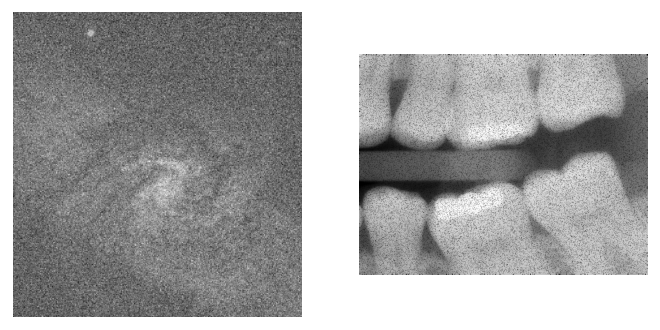

In [5]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray')
plt.axis('off')
plt.show()

###arithmetic mean

In [17]:
SS = 19
ss = int((SS - 1) / 2)

r_mean1 = np.zeros(np.shape(f1))
for x in range(ss, np.size(f1, 0) - ss):
  for y in range(ss, np.size(f1, 1) - ss):
    Sxy = f1[x - ss : x - ss + SS, y - ss : y - ss + SS]
    r_mean1[x, y] = np.mean(Sxy)

r_mean2 = np.zeros(np.shape(f2))
for x in range(ss, np.size(f2, 0) - ss):
  for y in range(ss, np.size(f2, 1) - ss):
    Sxy = f2[x - ss : x - ss + SS, y - ss : y - ss + SS]
    r_mean2[x, y] = np.mean(Sxy)

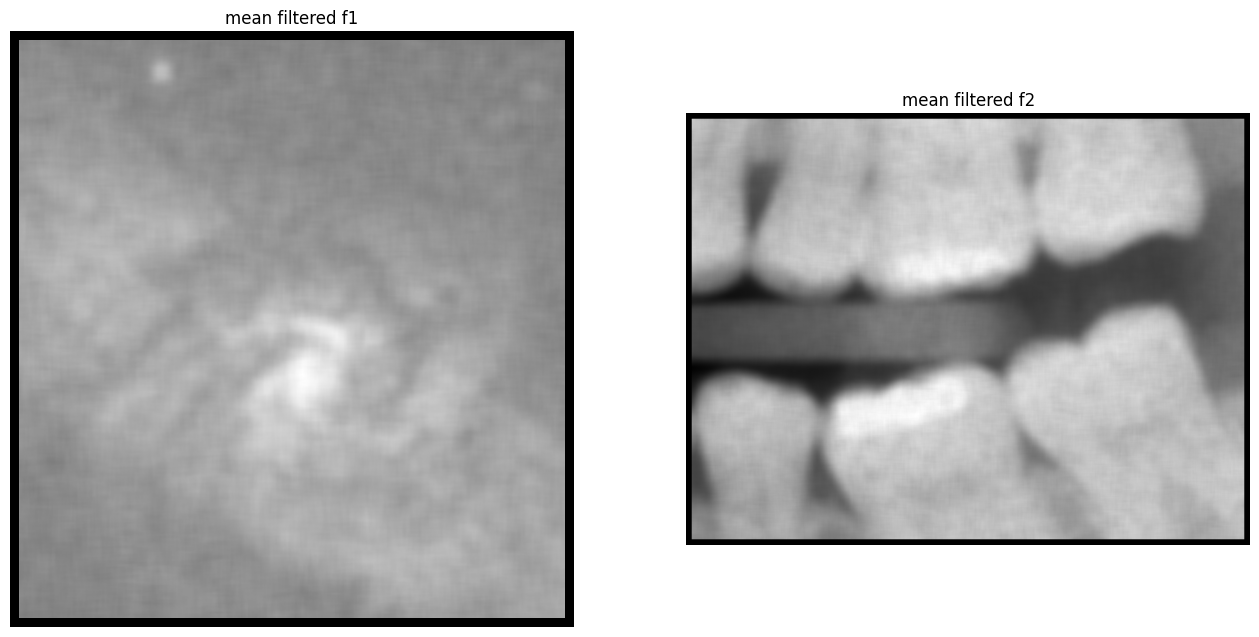

In [18]:
plt.figure(figsize=(16, 9))
plt.subplot(121)
plt.imshow(r_mean1, cmap='gray', aspect='equal')
plt.axis('off')
plt.title('mean filtered f1')

plt.subplot(122)
plt.imshow(r_mean2, cmap='gray', aspect='equal')
plt.axis('off')
plt.title('mean filtered f2')
plt.show()

###median

In [13]:
SS =  19 # kernel size (square kernel)
ss = int((SS-1)/2)
r_median = np.zeros(np.shape(f1))
r_mean = np.zeros(np.shape(f1))
for x in range(ss,np.size(f1,0)-ss):
  for y in range(ss,np.size(f1,1)-ss):
    Sxy = f1[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_median[x,y] = np.median(Sxy)
    r_mean[x,y] = np.mean(Sxy)

r_median2 = np.zeros(np.shape(f2))
r_mean2 = np.zeros(np.shape(f2))
for x in range(ss,np.size(f2,0)-ss):
  for y in range(ss,np.size(f2,1)-ss):
    Sxy = f2[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_median2[x,y] = np.median(Sxy)
    r_mean[x,y] = np.mean(Sxy)

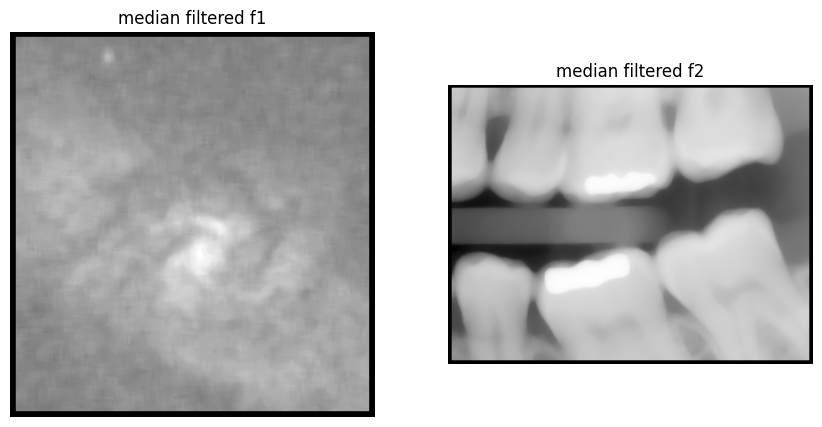

In [14]:
plt.figure(figsize=(16,9))
plt.subplot(132)
plt.imshow(r_median,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('median filtered f1')
plt.subplot(133)
plt.imshow(r_median2,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('median filtered f2')
plt.show()

###adaptive local noise reduction

In [21]:
std_eta = 16
SS = 3
ss = int((SS - 1) / 2)

r_amean = np.zeros(np.shape(f1))
for x in range(ss, np.size(f1, 0) - ss):
  for y in range(ss, np.size(f1, 1) - ss):
    Sxy = f1[x - ss : x - ss + SS, y - ss : y - ss + SS]
    mean_Sxy = np.mean(Sxy)
    std_Sxy = np.std(Sxy)


    var_Sxy = std_Sxy * std_Sxy
    var_eta = std_eta * std_eta

    if var_Sxy == 0:
      r_amean[x, y] = mean_Sxy
    else:
      ratio = min(
          max(var_eta / var_Sxy, 0), 1
      )
      r_amean[x, y] = f1[x, y] - (var_eta / var_Sxy) * (f1[x, y] - mean_Sxy)


r_amean2 = np.zeros(np.shape(f2))
for x in range(ss, np.size(f2, 0) - ss):
  for y in range(ss, np.size(f2, 1) - ss):
    Sxy = f2[x - ss : x - ss + SS, y - ss : y - ss + SS]
    mean_Sxy = np.mean(Sxy)
    std_Sxy = np.std(Sxy)

    var_Sxy = std_Sxy * std_Sxy
    var_eta = std_eta * std_eta

    if var_Sxy == 0:
      r_amean2[x, y] = mean_Sxy
    else:
      r_amean2[x, y] = f2[x, y] - (var_eta / var_Sxy) * (f2[x, y] - mean_Sxy)

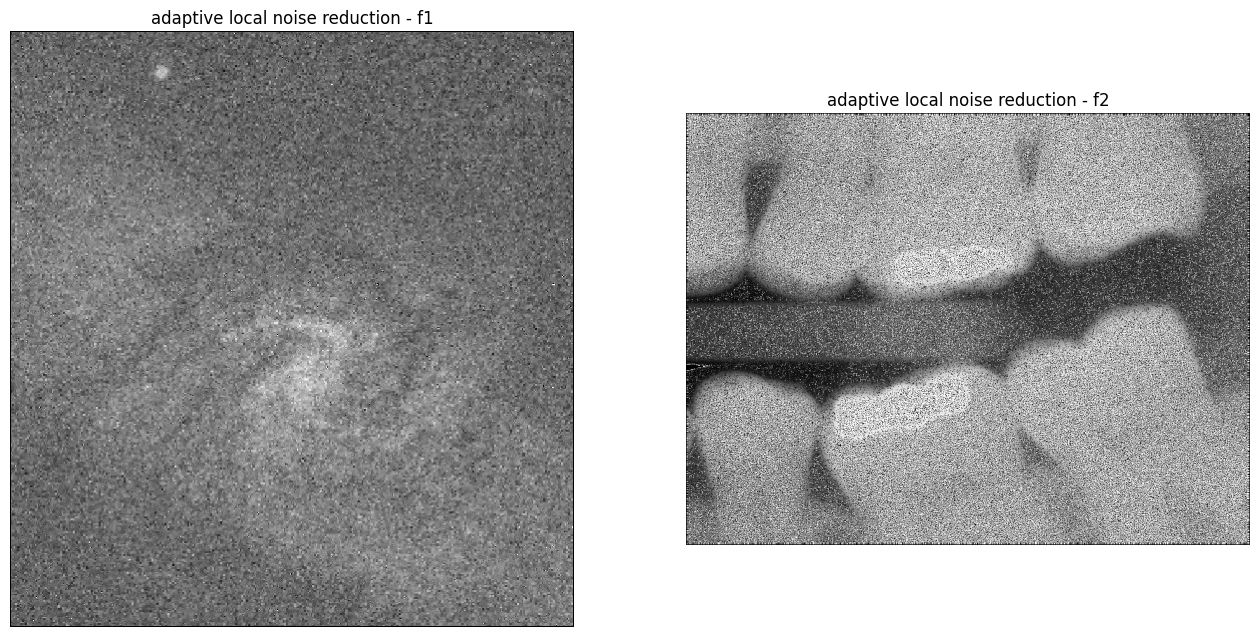

In [22]:
plt.figure(figsize=(16, 9))
plt.subplot(121)
plt.imshow(r_amean, cmap='gray', aspect='equal', vmin=0, vmax=255)
plt.axis('off')
plt.title('adaptive local noise reduction - f1')

plt.subplot(122)
plt.imshow(r_amean2, cmap='gray', aspect='equal', vmin=0, vmax=255)
plt.axis('off')
plt.title('adaptive local noise reduction - f2')
plt.show()